In [ ]:
"""
Initial data load and quick-clean pass.

"""
import pandas as pd
import numpy as np

# Load the raw Excel export of scraped vehicle listings
df = pd.read_excel('Vehicle_Data.xlsx')

# Normalize column headers (remove stray leading/trailing whitespace)
df.columns = df.columns.str.strip()

# Drop exact duplicate rows (repeated listings)
df = df.drop_duplicates().copy()

# --- Clean 'Price' ---
# Raw values look like "KSh 1,200,000" -> strip currency symbol and
# thousands separators, then coerce to numeric (invalid values -> NaN)
df['Price'] = (
    df['Price'].astype(str)
    .str.replace('KSh', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

# --- Clean 'Mileage' ---
# Remove thousands separators and treat the literal string
# "Unavailable" as a missing value before converting to numeric
df['Mileage'] = (
    df['Mileage'].astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
    .replace('Unavailable', np.nan)
)
df['Mileage'] = pd.to_numeric(df['Mileage'], errors='coerce')

# --- Clean 'YOM' (Year of Manufacture) ---
df['YOM'] = pd.to_numeric(df['YOM'], errors='coerce')

# Drop rows missing any field essential to modeling
df = df.dropna(subset=['Model', 'Make', 'YOM', 'Price', 'Mileage']).copy()

# Keep only plausible / valid ranges (guards against data-entry errors)
df = df[(df['YOM'] >= 1960) & (df['YOM'] <= 2026)]
df = df[(df['Price'] > 0) & (df['Mileage'] >= 0)]

# Standardize text fields
df['Make'] = df['Make'].str.strip()
df['Model'] = df['Model'].str.strip()
df['Location'] = df['Location'].str.split(',').str[0].str.strip()

# Quick sanity check of the cleaned exploratory frame
print(df.head())


     Model    Make     YOM   Color          Used Transmission   Mileage  \
0  X-Trail  Nissan  2014.0   Black  Foreign Used    Automatic  136000.0   
1    Teana  Nissan  2014.0  Silver  Foreign Used    Automatic   85000.0   
2    Teana  Nissan  2013.0    Gray  Foreign Used    Automatic   90231.0   
3  X-Trail  Nissan  2014.0   White  Foreign Used    Automatic   52000.0   
6  Qashqai  Nissan  2014.0   Black  Foreign Used       Manual  115000.0   

  Location      Price  
0  Nairobi  2050000.0  
1  Nairobi  1380000.0  
2  Nairobi   995000.0  
3  Nairobi  2500000.0  
6  Nairobi  1950000.0  


## Libraries

Load all libraries required for data manipulation, visualization, preprocessing, modeling and evaluation.

In [ ]:
"""
Imports and dataset load for the modeling workflow.

"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Load the raw dataset fresh for the cleaning pipeline below
df = pd.read_excel('Vehicle_Data.xlsx')

# Preview shape and first few rows to confirm the load worked
print(df.head())
print(df.shape)


     Model    Make   YOM   Color          Used Transmission      Mileage  \
0  X-Trail  Nissan  2014   Black  Foreign Used    Automatic       136000   
1    Teana  Nissan  2014  Silver  Foreign Used    Automatic        85000   
2    Teana  Nissan  2013    Gray  Foreign Used    Automatic        90231   
3  X-Trail  Nissan  2014   White  Foreign Used    Automatic        52000   
4     Note  Nissan  2014   White  Foreign Used    Automatic  Unavailable   

               Location          Price  
0        Nairobi, Karen  KSh 2,050,000  
1     Nairobi, Kilimani  KSh 1,380,000  
2    Nairobi, Ridgeways    KSh 995,000  
3      Nairobi, Jamhuri  KSh 2,500,000  
4  Mombasa, Mombasa CBD  KSh 1,100,000  
(46685, 9)


## Data Cleaning and Preprocessing

Full cleaning pipeline: fix data types, standardize text, handle missing values, filter invalid records, and engineer new features used by the models.

In [ ]:
# Normalize column headers
df.columns = df.columns.str.strip()

# Remove duplicate listings
df = df.drop_duplicates().copy()

# --- Clean 'Price': strip currency symbol/thousands separators, coerce numeric ---
df['Price'] = (
    df['Price'].astype(str)
    .str.replace('KSh', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

# --- Clean 'Mileage': strip separators, treat placeholder text as missing ---
df['Mileage'] = (
    df['Mileage'].astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
    .replace(['Unavailable', 'N/A', 'None', ''], np.nan)
)
df['Mileage'] = pd.to_numeric(df['Mileage'], errors='coerce')

# --- Convert Year of Manufacture to numeric ---
df['YOM'] = pd.to_numeric(df['YOM'], errors='coerce')

# --- Standardize 'Location' to county-level only (drop sub-area detail) ---
df['Location'] = (
    df['Location'].astype(str)
    .str.split(',')
    .str[0]
    .str.strip()
    .str.title()
)

# --- Standardize free-text categorical columns to Title Case ---
for col in ['Make', 'Model', 'Transmission', 'Fuel Type']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# Drop rows missing any field that is essential for modeling
df = df.dropna(subset=['Make', 'Model', 'YOM', 'Price', 'Mileage'])

# Normalize inconsistent "missing" representations ('nan' strings, blanks)
# so downstream imputers correctly detect them as NaN
for col in ['Model', 'Make', 'Color', 'Used', 'Transmission', 'Location']:
    df[col] = (
        df[col]
        .replace('nan', np.nan)
        .replace('', np.nan)
    )

# Fill remaining categorical gaps with an explicit "Unknown" label
# (keeps the record instead of dropping it, and lets the model learn
# from "unknown" as its own category)
for col in ['Color', 'Used', 'Transmission', 'Location']:
    df[col] = df[col].fillna('Unknown')

# Confirm no unexpected missing values remain
print(df.isna().sum()[df.isna().sum() > 0])

# Filter out implausible records (bad scrapes / data-entry errors)
df = df[
    (df['YOM'].between(1960, 2026)) &
    (df['Price'] > 0) &
    (df['Mileage'] >= 0)
].copy()

# --- Feature engineering ---
# Age of the vehicle in years, relative to current year
current_year = 2026
df['Age'] = current_year - df['YOM']

# Mileage accumulated per year of ownership (+1 avoids divide-by-zero for new cars)
df['Mileage_per_Year'] = df['Mileage'] / (df['Age'] + 1)

# Log-transform the skewed target and mileage to stabilize variance
# and make relationships closer to linear for the linear model
df['LogPrice'] = np.log1p(df['Price'])
df['LogMileage'] = np.log1p(df['Mileage'])

# Reset index after all the filtering above
df.reset_index(drop=True, inplace=True)

print(df.shape)
print(df[['Price', 'LogPrice']].head())


Series([], dtype: int64)
(32222, 13)
       Price   LogPrice
0  2050000.0  14.533351
1  1380000.0  14.137595
2   995000.0  13.810499
3  2500000.0  14.731802
4  1950000.0  14.483340


## Exploratory Data Analysis (EDA)

Visualize the target distribution, key relationships, and correlations to guide feature selection and modeling choices.

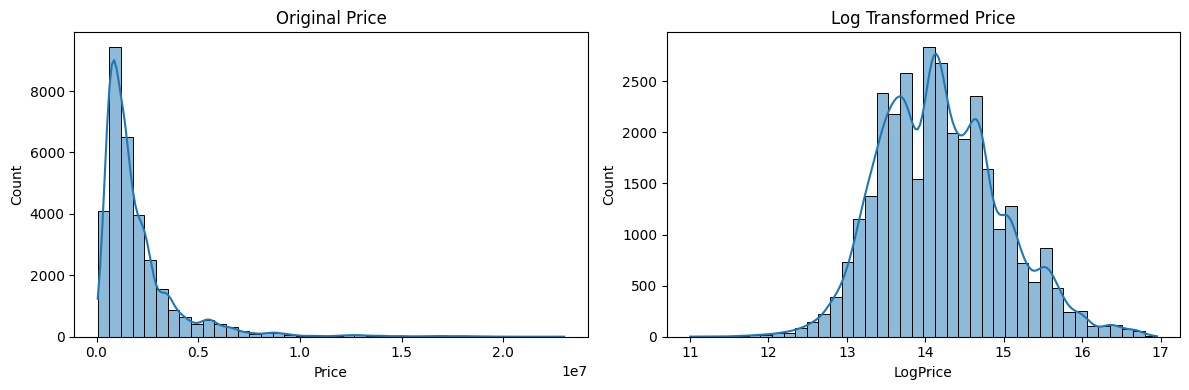

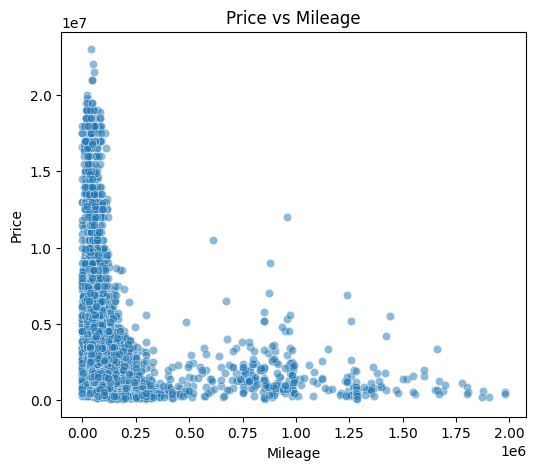

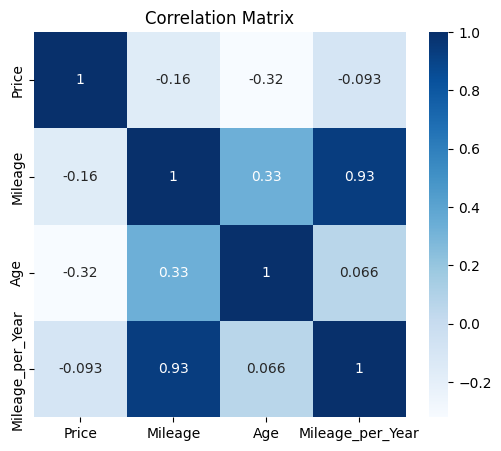

Make
Toyota           14070
Nissan            4007
Subaru            2160
Mazda             2014
Honda             1496
Volkswagen        1255
Mitsubishi        1226
Mercedes-Benz     1165
Suzuki            1104
Bmw               1047
Name: count, dtype: int64


In [ ]:
# Compare the raw Price distribution against its log-transformed version
# (the log transform should look noticeably more symmetric/normal)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['Price'], bins=40, kde=True)
plt.title('Original Price')

plt.subplot(1, 2, 2)
sns.histplot(df['LogPrice'], bins=40, kde=True)
plt.title('Log Transformed Price')

plt.tight_layout()
plt.show()

# Inspect the relationship between mileage and price
plt.figure(figsize=(6, 5))
sns.scatterplot(x='Mileage', y='Price', data=df, alpha=0.5)
plt.title('Price vs Mileage')
plt.show()

# Correlation matrix for the numeric features that will feed the models
corr = df[['Price', 'Mileage', 'Age', 'Mileage_per_Year']].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='Blues')
plt.title('Correlation Matrix')
plt.show()

# Most frequently listed vehicle makes in the dataset
print(df['Make'].value_counts().head(10))


## Features and Target

Define the model inputs (X) and target (y), build the preprocessing pipeline (imputation + one-hot encoding), and split into train/test sets.

In [ ]:
# Select the columns the models will use as predictors
X = df[['Make', 'Model', 'Transmission', 'Used',
        'Location', 'LogMileage', 'Age', 'Mileage_per_Year']]

# Target: log-transformed price (models predict on the log scale;
# we exponentiate predictions back to KES later)
y = df['LogPrice']

numeric_features = ['LogMileage', 'Age', 'Mileage_per_Year']
categorical_features = ['Make', 'Model', 'Transmission', 'Used', 'Location']

# Numeric pipeline: fill any missing numeric values with the median
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical pipeline: fill missing values with the most frequent
# category, then one-hot encode (unseen categories at inference
# time are safely ignored rather than raising an error)
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines into a single ColumnTransformer so it can be
# embedded directly inside each model's Pipeline (this is what makes
# the trained model safe to persist and reuse for deployment: raw
# inputs go in, encoded features come out, all in one saved object)
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Hold out 20% of the data for unbiased evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## Train the Models

Fit three candidate models — Linear Regression, Random Forest, and XGBoost — each wrapped in a pipeline with the shared preprocessor so they can be trained, evaluated, and later saved consistently.

In [ ]:
# Baseline model: Multiple Linear Regression
mlr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Random Forest: captures non-linear relationships and interactions
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# XGBoost: gradient-boosted trees, typically the strongest performer
# on structured/tabular data like this
xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective='reg:squarederror'
    ))
])

# Fit all three models on the training split
mlr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

print('Models trained successfully.')


Models trained successfully.


## Five-Fold Cross-Validation

Estimate each model's generalization error using 5-fold CV on the training data, to sanity-check performance before touching the held-out test set.

In [ ]:
# 5-fold split, shuffled for a representative mix in each fold
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in [('MLR', mlr_model),
                     ('Random Forest', rf_model),
                     ('XGBoost', xgb_model)]:

    # Negative RMSE is sklearn's convention for scoring (higher = better),
    # so we negate it back to a normal, positive RMSE for reporting
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )

    print(f'{name} CV RMSE: {-scores.mean():.4f} \u00b1 {scores.std():.4f}')


MLR CV RMSE: 0.2154 ± 0.0059
Random Forest CV RMSE: 0.2725 ± 0.0051
XGBoost CV RMSE: 0.2339 ± 0.0059


## Evaluation on Test Set

Score each trained model on the untouched test set, converting predictions back from log-price to KES before computing RMSE, MAPE, and R².

In [ ]:
def evaluate_model(name, model, X_test, y_test):
    """
    Evaluate a fitted model on the test set and print RMSE, MAPE, and R^2
    on the ORIGINAL price scale (KES), not the log scale it was trained on.
    """
    y_pred_log = model.predict(X_test)

    # Convert predictions and ground truth back from log-price to KES
    y_pred = np.expm1(y_pred_log)
    y_true = np.expm1(y_test)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)

    print(f'\n{name}')
    print(f'RMSE: KES {rmse:,.0f}')
    print(f'MAPE: {mape:.2f}%')
    print(f'R\u00b2: {r2:.4f}')

    return y_true, y_pred

# Evaluate all three models on the same held-out test set for a fair comparison
y_true, mlr_pred = evaluate_model('Multiple Linear Regression', mlr_model, X_test, y_test)
_, rf_pred = evaluate_model('Random Forest', rf_model, X_test, y_test)
_, xgb_pred = evaluate_model('XGBoost', xgb_model, X_test, y_test)



Multiple Linear Regression
RMSE: KES 775,967
MAPE: 14.74%
R²: 0.8579

Random Forest
RMSE: KES 809,880
MAPE: 20.03%
R²: 0.8452

XGBoost
RMSE: KES 817,095
MAPE: 17.26%
R²: 0.8424


## Rare-Segment Evaluation

Check whether the model performs noticeably worse on rare vehicle makes (<2% of listings) versus common ones, since sparse categories are harder to learn.

In [ ]:
# Identify makes that represent less than 2% of all listings
brand_freq = df['Make'].value_counts(normalize=True)
rare_brands = brand_freq[brand_freq < 0.02].index.tolist()

# Build a comparison frame of actual vs predicted price (XGBoost) on the test set
test_df = X_test.copy()
test_df['Actual'] = np.expm1(y_test)
test_df['Predicted'] = xgb_pred
test_df['Make'] = X_test['Make']

# Tag each row as belonging to a "Rare" or "Common" make
test_df['Segment'] = np.where(
    test_df['Make'].isin(rare_brands),
    'Rare',
    'Common'
)

# Compare error (MAPE) between the two segments
segment_results = test_df.groupby('Segment').apply(
    lambda g: np.mean(np.abs((g['Actual'] - g['Predicted']) / g['Actual'])) * 100
)

print('\nMAPE by Segment')
print(segment_results)



MAPE by Segment
Segment
Common    16.957828
Rare      21.825278
dtype: float64


/tmp/ipykernel_1418/1168545376.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  segment_results = test_df.groupby('Segment').apply(


## Feature Importance (Random Forest)

Inspect which encoded features the Random Forest relies on most, to sanity-check that the model is learning sensible signal (e.g. mileage, age, make) rather than noise.

                     Feature  Importance
1                   num__Age    0.264156
311          cat__Model_Land    0.193708
15      cat__Make_Land Rover    0.074768
16           cat__Make_Lexus    0.043870
25          cat__Make_Suzuki    0.032366
21          cat__Make_Nissan    0.031693
18   cat__Make_Mercedes-Benz    0.028144
284         cat__Model_Hilux    0.026997
278       cat__Model_Harrier    0.023438
212         cat__Model_Demio    0.018579
26          cat__Make_Toyota    0.017198
250           cat__Model_Fit    0.016406
7         cat__Make_Daihatsu    0.016001
0            num__LogMileage    0.015240
497       cat__Model_X-Trail    0.013308


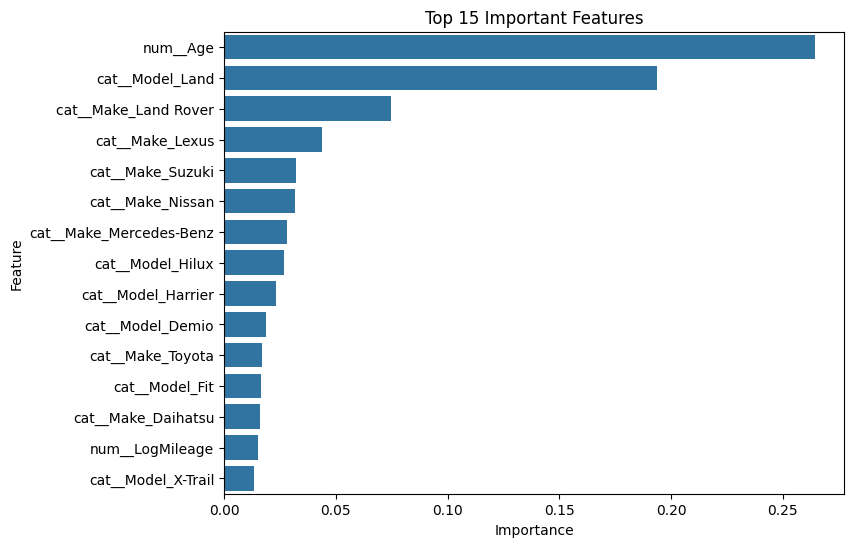

In [ ]:
# Pull the fitted RandomForestRegressor out of the pipeline
rf_estimator = rf_model.named_steps['model']

# Get the expanded feature names produced by the ColumnTransformer
# (numeric names unchanged, categorical names expanded by one-hot encoding)
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_estimator.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df.head(15))

# Visualize the top 15 most important features
plt.figure(figsize=(8, 6))
sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)
plt.title('Top 15 Important Features')
plt.show()


## SHAP Explainability

Use SHAP values to explain, feature by feature, how the Random Forest arrives at its predictions — useful for building trust in the model before deploying it.

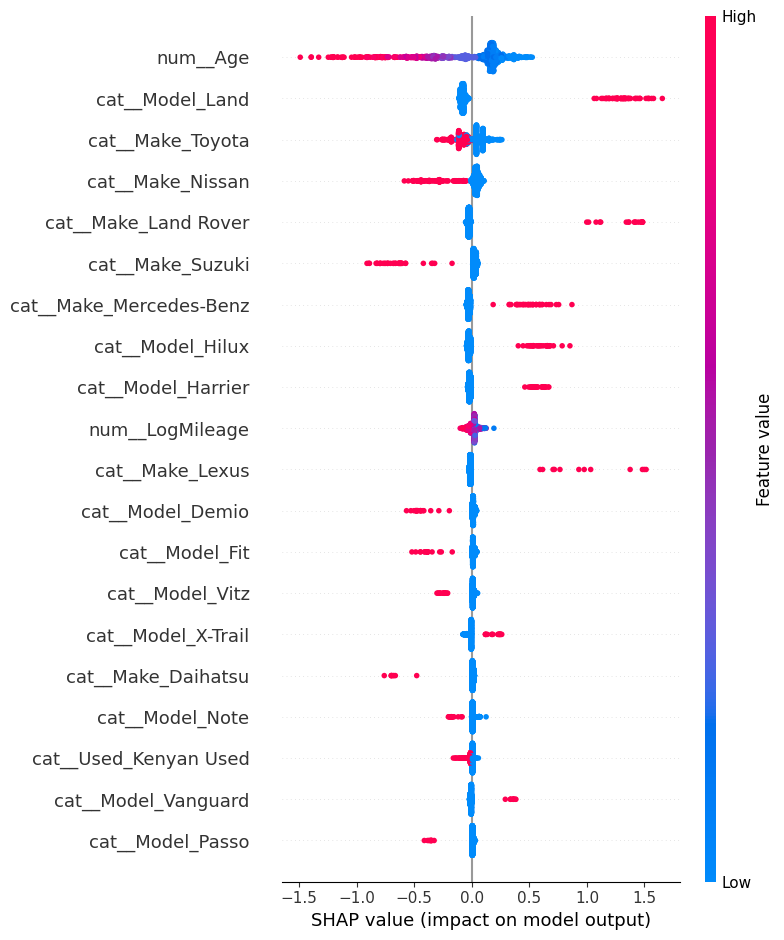

In [ ]:
# Install SHAP if it isn't already available in this environment
!pip install shap

import shap

# Apply the fitted preprocessor to the training data to get the
# same encoded feature matrix the model was trained on
X_train_transformed = rf_model.named_steps['preprocessor'].transform(X_train)

# SHAP's TreeExplainer expects a dense array; one-hot encoding
# produces a sparse matrix, so convert it
X_train_transformed_dense = X_train_transformed.toarray()

# Explaining the full training set can be slow — use a representative sample
sample_size = min(1000, X_train_transformed_dense.shape[0])
X_sample = X_train_transformed_dense[:sample_size]

# Build the explainer directly from the trained tree ensemble
explainer = shap.TreeExplainer(rf_estimator)
shap_values = explainer.shap_values(X_sample)

# Summary plot: shows each feature's overall impact on the model's output
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_names
)


## Actual vs Predicted Plot

Visual diagnostic: points close to the diagonal line indicate accurate XGBoost predictions; systematic deviation would flag bias.

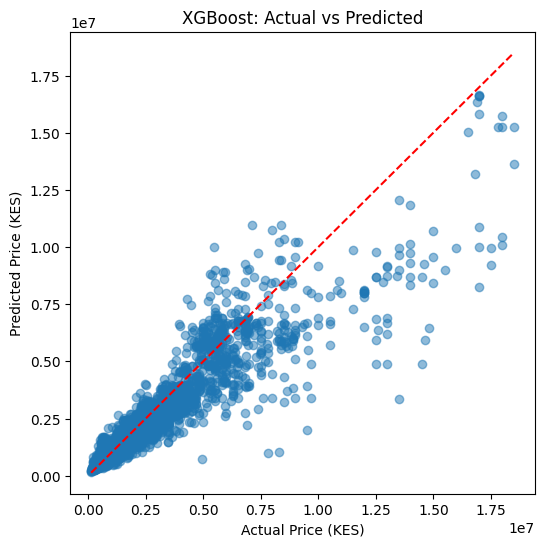

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_true, xgb_pred, alpha=0.5)

# Diagonal reference line: a perfect model would put every point on this line
plt.plot(
    [y_true.min(), y_true.max()],
    [y_true.min(), y_true.max()],
    'r--'
)

plt.xlabel('Actual Price (KES)')
plt.ylabel('Predicted Price (KES)')
plt.title('XGBoost: Actual vs Predicted')
plt.show()
